# E2: Listing Feature Experiments

F0 matches the original five-feature baseline semantically: month index, flat age, floor area, flat type, and town. The original notebook names floor area `floor_area_sqm`; shared code uses `FLOOR_AREA_SQM`. This experiment follows the shared cleaning and fixed time split, not the original raw-data loading.

E2.1–E2.4 each add only their specified feature(s) to F0. E2.5 uses the full eight-column listing core in canonical `make_listing` order. Every E2 row is compared with E2.0; positive `delta_rmse` means improvement. `composite_block_id` is a JSON tuple of town, block, and street, preserving component boundaries and representing missing components as null. It uses no labels.

E2.4 joins the HDB table through existing helpers and selects only latitude and longitude as additional model inputs. The historical HDB snapshot cannot independently establish as-of availability of every block attribute. E3 is available in the separate auxiliary integration notebook.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'src').is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from experiments.feature_engineering.utils.core import *
from IPython.display import display, Image


In [2]:
assert (AUDITS / 'selected_encoding.json').exists(), 'Run encoding_comparison.ipynb first.'
results = stage2()
display(results)

E2.0 ordinal {'RMSE': 485.156855, 'MAE': 361.49009, 'R2': 0.45752, 'Mean Error': -45.318633}


/Users/wangyufan/Desktop/master/CS5228/project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


E2.1 ordinal {'RMSE': 484.366621, 'MAE': 360.785046, 'R2': 0.459285, 'Mean Error': -44.74357}


E2.2 ordinal {'RMSE': 481.022704, 'MAE': 357.975964, 'R2': 0.466725, 'Mean Error': -44.132149}


E2.3 ordinal {'RMSE': 482.755909, 'MAE': 359.026282, 'R2': 0.462875, 'Mean Error': -43.94113}


E2.4 ordinal {'RMSE': 479.44573, 'MAE': 356.39261, 'R2': 0.470216, 'Mean Error': -46.422075}


/Users/wangyufan/Desktop/master/CS5228/project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


E2.5 ordinal {'RMSE': 479.496863, 'MAE': 356.508969, 'R2': 0.470103, 'Mean Error': -45.033072}


Matplotlib is building the font cache; this may take a moment.


,experiment,encoding,low_card_encoding,raw_features,raw_feature_count,encoded_features,feature_count,categorical_features,model_params,train_rows,validation_rows,encoding_seconds,training_seconds,RMSE,MAE,R2,Mean Error,control,delta_rmse,relative_improvement_pct
0,E2.0,ordinal,onehot,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",5,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",33,[],"{""learning_rate"": 0.05, ""n_estimators"": 500, ""...",117777,31582,0.078022,2.759973,485.156855,361.490090,0.457520,-45.318633,E2.0,0.000000,0.000000
1,E2.1,ordinal,onehot,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",6,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",51,[],"{""learning_rate"": 0.05, ""n_estimators"": 500, ""...",117777,31582,0.108513,2.223005,484.366621,360.785046,0.459285,-44.743570,E2.0,0.790234,0.162882
2,E2.2,ordinal,onehot,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",6,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",34,[],"{""learning_rate"": 0.05, ""n_estimators"": 500, ""...",117777,31582,0.212669,2.324342,481.022704,357.975964,0.466725,-44.132149,E2.0,4.134151,0.852127
3,E2.3,ordinal,onehot,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",6,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",34,[],"{""learning_rate"": 0.05, ""n_estimators"": 500, ""...",117777,31582,0.136293,2.239536,482.755909,359.026282,0.462875,-43.941130,E2.0,2.400946,0.494880
4,E2.4,ordinal,onehot,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",7,"[""month_index"", ""flat_age"", ""FLOOR_AREA_SQM"", ...",35,[],"{""learning_rate"": 0.05, ""n_estimators"": 500, ""...",117777,31582,0.098348,2.632211,479.445730,356.392610,0.470216,-46.422075,E2.0,5.711125,1.177171
5,E2.5,ordinal,onehot,"[""FLOOR_AREA_SQM"", ""flat_age"", ""month_index"", ...",8,"[""FLOOR_AREA_SQM"", ""flat_age"", ""month_index"", ...",53,[],"{""learning_rate"": 0.05, ""n_estimators"": 500, ""...",117777,31582,0.209432,2.433807,479.496863,356.508969,0.470103,-45.033072,E2.0,5.659992,1.166631


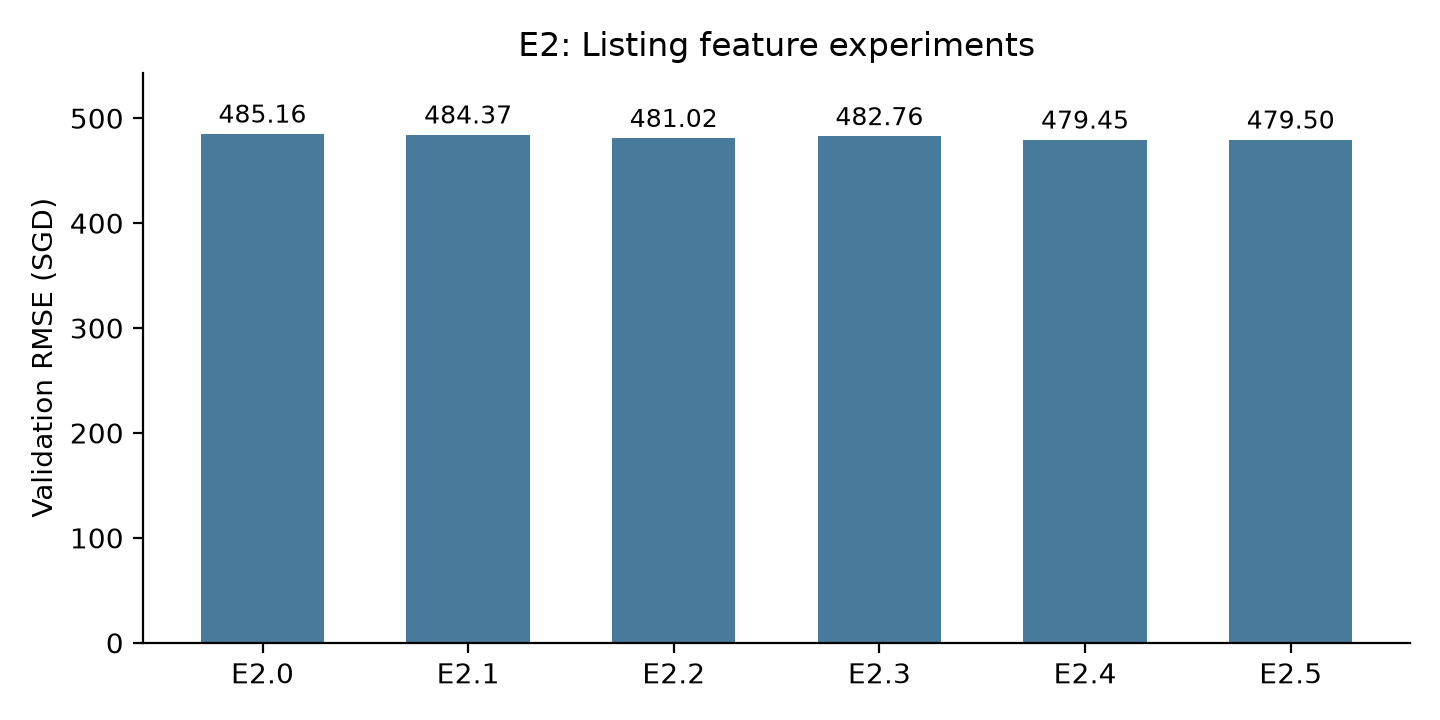

In [3]:
display(Image(filename=str(FIGURES / 'e2_rmse.png')))

All models use the selected high-cardinality encoder and existing low-cardinality one-hot encoder. Numerical missing values remain NaN. Assertions enforce row/label alignment, identical encoded schemas, finite predictions/metrics, native categorical recognition, and equality of E2.5 metrics with the selected encoding-comparison run. E3 is not executed by this notebook.

Final interpretation is consolidated in `analysis/feature_engineering_results_zh.md`. This notebook reproduces E2 only.